# 04 · Evaluation (tasks 14–17)
1. Rebuild every model's validation scores (scikit-learn models are refit with the settings chosen in 03; the
   CNN is loaded from `results/cnn.keras`).
2. **Task 15:** choose each model's threshold on validation for at least 95% sensitivity, then freeze it.
3. **Task 16:** score the test set once, with bootstrap 95% CIs.
4. **Task 17:** error analysis of the CNN's test mistakes.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, average_precision_score, precision_recall_curve, roc_curve
from sklearn.pipeline import make_pipeline

from config import DATA_DIR, FIG_DIR, RESULTS_DIR, SEED, set_seeds
from src.metrics import bootstrap_ci, evaluate, threshold_for_sensitivity

set_seeds()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TARGET_SENS = 0.95

d = np.load(DATA_DIR / "processed.npz")
Xtr, ytr, Xva, yva = d["flat_train"], d["y_train"], d["flat_val"], d["y_val"]
Iva = d["img_val"]

## Rebuild the models (settings from 03)

In [2]:
import tensorflow as tf
from tensorflow import keras

models = {
    "It0 majority": DummyClassifier(strategy="most_frequent").fit(Xtr, ytr),
    "It1 logistic regression": LogisticRegression(C=0.01, class_weight="balanced", max_iter=2000,
                                                  random_state=SEED).fit(Xtr, ytr),
    "It2 PCA + random forest": make_pipeline(
        PCA(n_components=50, random_state=SEED),
        RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED),
    ).fit(Xtr, ytr),
}
cnn = keras.models.load_model(RESULTS_DIR / "cnn.keras")

def score(name, split):
    if name == "It3 CNN":
        return cnn.predict(d[f"img_{split}"], verbose=0).ravel()
    return models[name].predict_proba(d[f"flat_{split}"])[:, 1]

NAMES = list(models) + ["It3 CNN"]
val_scores = {n: score(n, "val") for n in NAMES}

## Task 14 · Metrics pipeline, and Task 15 · thresholds chosen on validation
For each model we take the highest threshold that keeps validation sensitivity at or above 95%. That gives the
best specificity the model can offer under our "miss as few pneumonia cases as possible" requirement.
The majority baseline has constant scores, so it keeps 0.5.

In [3]:
thresholds = {}
rows = []
for n in NAMES:
    t = 0.5 if n == "It0 majority" else threshold_for_sensitivity(yva, val_scores[n], TARGET_SENS)
    thresholds[n] = t
    rows.append({"model": n, "threshold": t, **evaluate(yva, val_scores[n], t)})
val_table = pd.DataFrame(rows)
cols = ["model", "threshold", "auc", "sensitivity", "specificity", "precision", "f1", "balanced_acc", "fn", "fp"]
val_table[cols].round(3)

,model,threshold,auc,sensitivity,specificity,precision,f1,balanced_acc,fn,fp
0,It0 majority,0.500,0.500,1.000,0.000,0.742,0.852,0.500,0,135
1,It1 logistic regression,0.504,0.992,0.951,0.963,0.987,0.969,0.957,19,5
2,It2 PCA + random forest,0.547,0.987,0.954,0.933,0.976,0.965,0.944,18,9
3,It3 CNN,0.061,0.992,0.951,0.970,0.989,0.970,0.961,19,4


**Findings.** At the 95%-sensitivity thresholds the three real models look almost identical on validation
(sensitivity 0.95, specificity 0.93–0.97). The CNN's threshold is only 0.06: class weighting makes it
under-confident about pneumonia, so the default 0.5 was far too strict (see 03).

Thresholds are now frozen. Everything below is the **single** test-set evaluation.

## Task 16 · Test set, scored once, with bootstrap 95% CIs (1,000 resamples)

In [4]:
yte = d["y_test"]
test_scores = {n: score(n, "test") for n in NAMES}
rows = []
for n in NAMES:
    m = evaluate(yte, test_scores[n], thresholds[n])
    ci = bootstrap_ci(yte, test_scores[n], thresholds[n], n_boot=1000, seed=SEED)
    rows.append({"model": n, "threshold": thresholds[n], **m,
                 "auc_ci": "{:.3f}–{:.3f}".format(*ci["auc_ci"]),
                 "sens_ci": "{:.3f}–{:.3f}".format(*ci["sensitivity_ci"]),
                 "spec_ci": "{:.3f}–{:.3f}".format(*ci["specificity_ci"])})
test_table = pd.DataFrame(rows)
test_table.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)
test_table[["model", "threshold", "auc", "auc_ci", "sensitivity", "sens_ci", "specificity", "spec_ci",
            "precision", "f1", "balanced_acc", "fn", "fp"]].round(3)

,model,threshold,auc,auc_ci,sensitivity,sens_ci,specificity,spec_ci,precision,f1,balanced_acc,fn,fp
0,It0 majority,0.500,0.500,0.500–0.500,1.000,1.000–1.000,0.000,0.000–0.000,0.625,0.769,0.500,0,234
1,It1 logistic regression,0.504,0.930,0.904–0.954,0.972,0.955–0.987,0.709,0.647–0.767,0.848,0.906,0.841,11,68
2,It2 PCA + random forest,0.547,0.941,0.922–0.960,0.936,0.910–0.959,0.774,0.718–0.827,0.873,0.903,0.855,25,53
3,It3 CNN,0.061,0.961,0.946–0.974,0.969,0.951–0.985,0.722,0.662–0.780,0.853,0.908,0.846,12,65


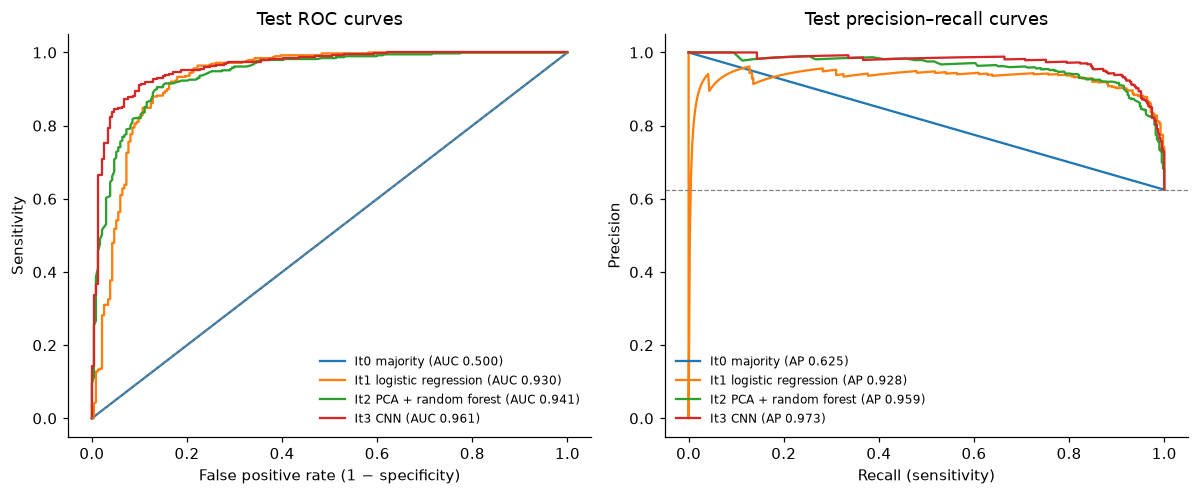

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for n in NAMES:
    fpr, tpr, _ = roc_curve(yte, test_scores[n])
    auc = test_table.set_index("model").loc[n, "auc"]
    axes[0].plot(fpr, tpr, label=f"{n} (AUC {auc:.3f})")
    p, r, _ = precision_recall_curve(yte, test_scores[n])
    axes[1].plot(r, p, label=f"{n} (AP {average_precision_score(yte, test_scores[n]):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="grey", lw=0.8)
axes[0].set(xlabel="False positive rate (1 − specificity)", ylabel="Sensitivity", title="Test ROC curves")
axes[1].axhline(yte.mean(), ls="--", color="grey", lw=0.8)
axes[1].set(xlabel="Recall (sensitivity)", ylabel="Precision", title="Test precision–recall curves")
for a in axes:
    a.legend(frameon=False, fontsize=8, loc="lower left" if a is axes[1] else "lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig9_test_roc_pr.png")
plt.show()

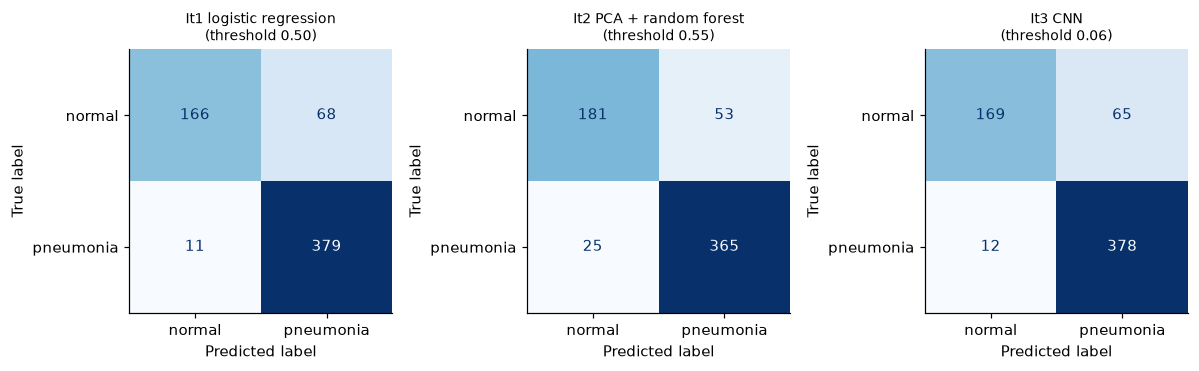

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for a, n in zip(axes, NAMES[1:]):
    y_pred = (test_scores[n] >= thresholds[n]).astype(int)
    ConfusionMatrixDisplay.from_predictions(yte, y_pred, display_labels=["normal", "pneumonia"],
                                            cmap="Blues", colorbar=False, ax=a)
    a.set_title(f"{n}\n(threshold {thresholds[n]:.2f})", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig10_test_confusion.png")
plt.show()

**Findings (test).**
- **All models drop from validation to test**, as the distribution shift seen in 01_eda predicted
  (logistic regression AUC 0.992 → 0.930).
- **The CNN degrades least and is the best model on test:** AUC 0.961 (95% CI 0.946–0.974) vs 0.930
  (0.904–0.954) for logistic regression. The CIs barely overlap. Its learned spatial features transfer
  better than raw pixels.
- **The sensitivity target held on test** for the CNN (0.969, CI 0.951–0.985; 12 of 390 pneumonia cases
  missed) and for logistic regression (0.972). It slipped for the random forest (0.936).
- **The price is specificity:** about 0.72 for the CNN, i.e. 65 of 234 normal X-rays flagged. For a triage
  tool that is acceptable (a false alarm costs a second look), but it is the main weakness to report.

## Task 17 · Error analysis (CNN, test set)

false negative (missed pneumonia): 12
false positive (normal flagged): 65


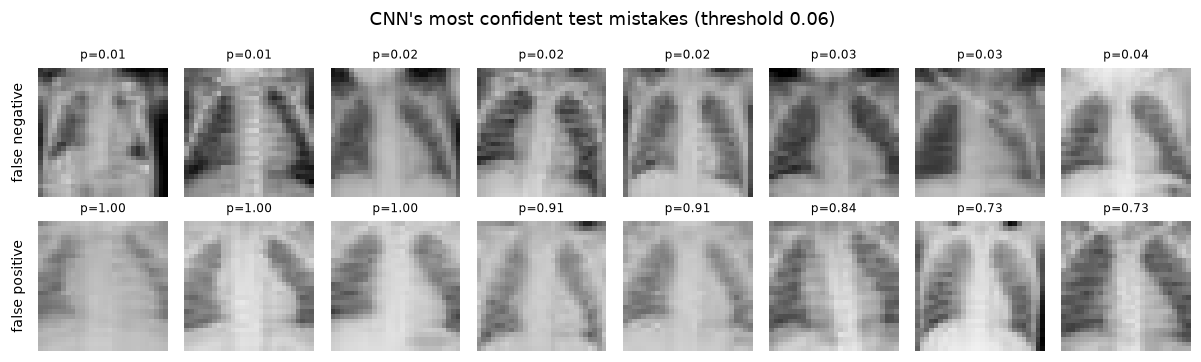

In [7]:
n = "It3 CNN"
s, t = test_scores[n], thresholds[n]
pred = (s >= t).astype(int)
Ite = d["img_test"][..., 0]
groups = {
    "false negative (missed pneumonia)": np.where((yte == 1) & (pred == 0))[0],
    "false positive (normal flagged)": np.where((yte == 0) & (pred == 1))[0],
}
for g, idx in groups.items():
    print(f"{g}: {len(idx)}")

fig, axes = plt.subplots(2, 8, figsize=(11, 3.4))
for row, (g, idx) in enumerate(groups.items()):
    # Most confident mistakes first: lowest scores for FNs, highest for FPs.
    order = idx[np.argsort(s[idx])] if row == 0 else idx[np.argsort(-s[idx])]
    for col in range(8):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(order):
            i = order[col]
            ax.imshow(Ite[i], cmap="gray", vmin=0, vmax=1)
            ax.set_title(f"p={s[i]:.2f}", fontsize=8)
    axes[row, 0].text(-0.1, 0.5, g.split(" (")[0], transform=axes[row, 0].transAxes,
                      ha="right", va="center", fontsize=9, rotation=90)
fig.suptitle(f"CNN's most confident test mistakes (threshold {t:.2f})")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig11_cnn_errors.png")
plt.show()

In [8]:
cats = {
    "TP": (yte == 1) & (pred == 1), "FN": (yte == 1) & (pred == 0),
    "TN": (yte == 0) & (pred == 0), "FP": (yte == 0) & (pred == 1),
}
err = pd.DataFrame([
    {"group": k, "n": int(m.sum()),
     "mean_brightness": Ite[m].mean() if m.any() else np.nan,
     "mean_score": s[m].mean() if m.any() else np.nan}
    for k, m in cats.items()
])
err.round(3)

,group,n,mean_brightness,mean_score
0,TP,378,0.571,0.841
1,FN,12,0.528,0.031
2,TN,169,0.548,0.015
3,FP,65,0.573,0.283


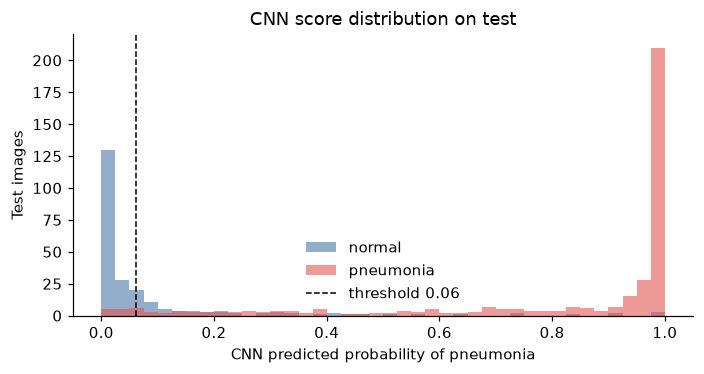

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
bins = np.linspace(0, 1, 41)
ax.hist(s[yte == 0], bins, alpha=0.6, label="normal", color="#4C78A8")
ax.hist(s[yte == 1], bins, alpha=0.6, label="pneumonia", color="#E45756")
ax.axvline(t, color="black", ls="--", lw=1, label=f"threshold {t:.2f}")
ax.set(xlabel="CNN predicted probability of pneumonia", ylabel="Test images", title="CNN score distribution on test")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig12_cnn_score_hist.png")
plt.show()

**Findings (errors).**
- **Missed pneumonia (12) are confident misses** (mean score 0.03) and are *darker* than correctly caught
  pneumonia (mean brightness 0.528 vs 0.571). Their lungs look relatively clear at 28×28, so the opacity
  that defines pneumonia is either subtle or lost at this resolution.
- **False alarms (65) are brighter** (0.573, the same as true pneumonia) and often look hazy or low-contrast.
  The model partly relies on overall brightness, which is also what differs between train and test (01_eda).
- **The score histogram shows a large overlap region** between 0.05 and 0.9 where both classes appear. These
  cases are where a radiologist's review matters most.
- **Next steps:** higher resolution (task 19, 64×64) and per-image contrast normalisation could reduce the
  brightness reliance.